<a href="https://colab.research.google.com/github/zzprogram/DSC1105/blob/main/FA4_CURIMATMAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
install.packages("devtools")
install.packages("remotes")

devtools::install_github("coatless/ucidata")

library(ucidata)
library(tidyverse)

data(wine)
str(wine)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Skipping install of 'ucidata' from a github remote, the SHA1 (0ce85595) has not changed since last install.
  Use `force = TRUE` to force installation



'data.frame':	6497 obs. of  13 variables:
 $ fixed_acidity       : num  7.4 7.8 7.8 11.2 7.4 7.4 7.9 7.3 7.8 7.5 ...
 $ volatile_acidity    : num  0.7 0.88 0.76 0.28 0.7 0.66 0.6 0.65 0.58 0.5 ...
 $ citric_acid         : num  0 0 0.04 0.56 0 0 0.06 0 0.02 0.36 ...
 $ residual_sugar      : num  1.9 2.6 2.3 1.9 1.9 1.8 1.6 1.2 2 6.1 ...
 $ chlorides           : num  0.076 0.098 0.092 0.075 0.076 0.075 0.069 0.065 0.073 0.071 ...
 $ free_sulfur_dioxide : num  11 25 15 17 11 13 15 15 9 17 ...
 $ total_sulfur_dioxide: num  34 67 54 60 34 40 59 21 18 102 ...
 $ density             : num  0.998 0.997 0.997 0.998 0.998 ...
 $ pH                  : num  3.51 3.2 3.26 3.16 3.51 3.51 3.3 3.39 3.36 3.35 ...
 $ sulphates           : num  0.56 0.68 0.65 0.58 0.56 0.56 0.46 0.47 0.57 0.8 ...
 $ alcohol             : num  9.4 9.8 9.8 9.8 9.4 9.4 9.4 10 9.5 10.5 ...
 $ quality             : int  5 5 5 6 5 5 5 7 7 5 ...
 $ color               : Factor w/ 2 levels "Red","White": 1 1 1 1 1 1 1 1 1 1 ...


1. There are a couple of outliers in *density*, remove them.

In [10]:
summary(wine$density)

Q1 <- quantile(wine$density, 0.25)
Q3 <- quantile(wine$density, 0.75)
IQR <- Q3 - Q1

lower_bound <- Q1 - 1.5 * IQR
upper_bound <- Q3 + 1.5 * IQR

wine_clean <- wine %>%
  filter(density >= lower_bound & density <= upper_bound)

head(wine_clean)
str(wine_clean)

cat("\n","Original rows:", nrow(wine), "\n")
cat("Cleaned rows:", nrow(wine_clean), "\n\n")
summary(wine_clean$density)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.9871  0.9923  0.9949  0.9947  0.9970  1.0390 

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<fct>
1,7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5,Red
2,7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5,Red
3,7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5,Red
4,11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6,Red
5,7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5,Red
6,7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5,Red


'data.frame':	6494 obs. of  13 variables:
 $ fixed_acidity       : num  7.4 7.8 7.8 11.2 7.4 7.4 7.9 7.3 7.8 7.5 ...
 $ volatile_acidity    : num  0.7 0.88 0.76 0.28 0.7 0.66 0.6 0.65 0.58 0.5 ...
 $ citric_acid         : num  0 0 0.04 0.56 0 0 0.06 0 0.02 0.36 ...
 $ residual_sugar      : num  1.9 2.6 2.3 1.9 1.9 1.8 1.6 1.2 2 6.1 ...
 $ chlorides           : num  0.076 0.098 0.092 0.075 0.076 0.075 0.069 0.065 0.073 0.071 ...
 $ free_sulfur_dioxide : num  11 25 15 17 11 13 15 15 9 17 ...
 $ total_sulfur_dioxide: num  34 67 54 60 34 40 59 21 18 102 ...
 $ density             : num  0.998 0.997 0.997 0.998 0.998 ...
 $ pH                  : num  3.51 3.2 3.26 3.16 3.51 3.51 3.3 3.39 3.36 3.35 ...
 $ sulphates           : num  0.56 0.68 0.65 0.58 0.56 0.56 0.46 0.47 0.57 0.8 ...
 $ alcohol             : num  9.4 9.8 9.8 9.8 9.4 9.4 9.4 10 9.5 10.5 ...
 $ quality             : int  5 5 5 6 5 5 5 7 7 5 ...
 $ color               : Factor w/ 2 levels "Red","White": 1 1 1 1 1 1 1 1 1 1 ...


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.9871  0.9923  0.9949  0.9947  0.9970  1.0037 

2. Make a scatterplot of *wine type* as a function of *total sulfur dioxide*. Add a loess smoother and a logistic regression smoother. Comment on similarities or differences. (Note: To do this, you will need to change wine type from white/red to 0/1.)

In [11]:
wine_clean <- wine_clean %>%
  mutate(wine_type = ifelse(color == "Red", 1, 0))

cat("Wine Type:", "\n")
table(wine_clean$color, wine_clean$wine_type)

Wine Type: 


       
           0    1
  Red      0 1599
  White 4895    0

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 14 rows containing missing values or values outside the scale range
(`geom_smooth()`).”


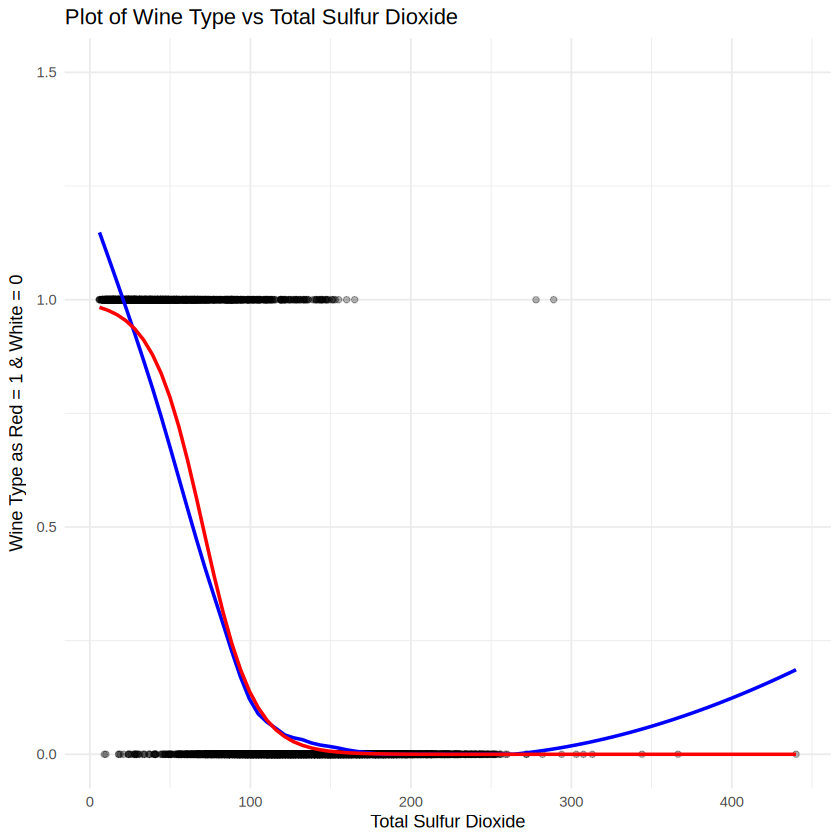

In [12]:
ggplot(wine_clean, aes(x = total_sulfur_dioxide, y = wine_type)) +
  geom_point(alpha = 0.3) +
  geom_smooth(method = "loess", color = "blue", se = FALSE) +
  geom_smooth(method = "glm", method.args = list(family = "binomial"),
                color = "red", se = FALSE) +
  ylim(0, 1.5) +
  labs(title = "Plot of Wine Type vs Total Sulfur Dioxide",
        x = "Total Sulfur Dioxide", y = "Wine Type as Red = 1 & White = 0") +
  theme_minimal()


Comment on similarities or differences:

3. Make a scatterplot of *wine type* as a function of *density*. Add a loess smoother and a logistic regression smoother.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_smooth()`).”


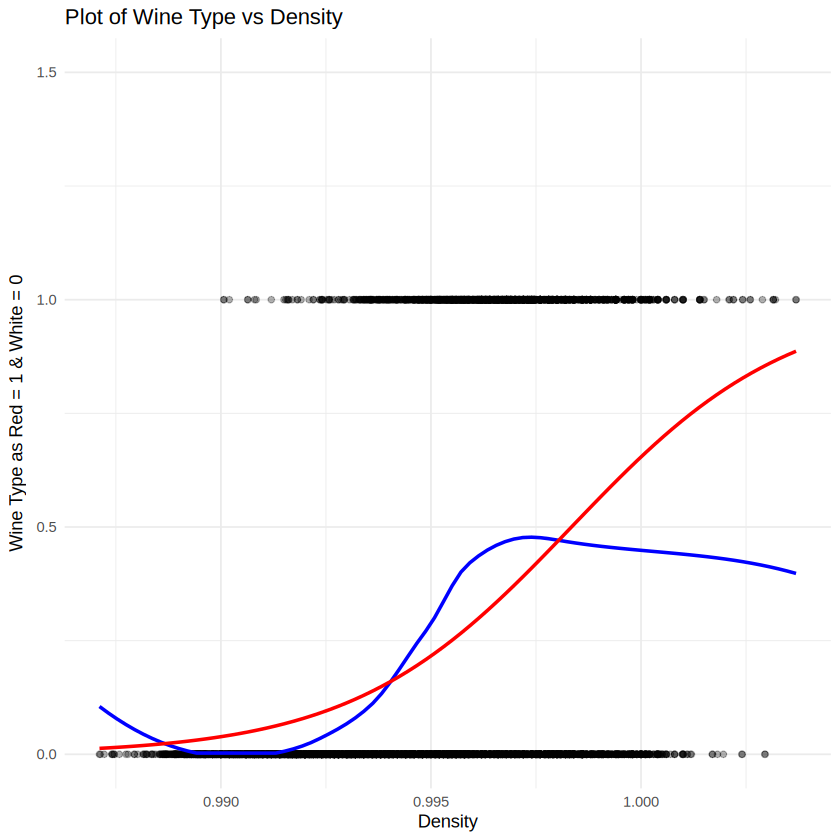

In [13]:
ggplot(wine_clean, aes(x = density, y = wine_type)) +
  geom_point(alpha = 0.3) +
  geom_smooth(method = "loess", color = "blue", se = FALSE) +
  geom_smooth(method = "glm", method.args = list(family = "binomial"),
                color = "red", se = FALSE) +
  ylim(0, 1.5) +
  labs(title = "Plot of Wine Type vs Density",
        x = "Density", y = "Wine Type as Red = 1 & White = 0") +
  theme_minimal()


Comment on similiraties or differences:

4. Fit two logistic regression models: one with no interaction between *density* and *total sulfur dioxide* and one with an interaction between *density* and *total sulfur dioxide*. Make two coplots for each model showing the fits. For each model, you should have one coplot of wine type as a function of *density* conditioned on *total sulfur dioxide*, and one with *wine type* as a function of *total sulfur dioxide* conditioned on *density*.

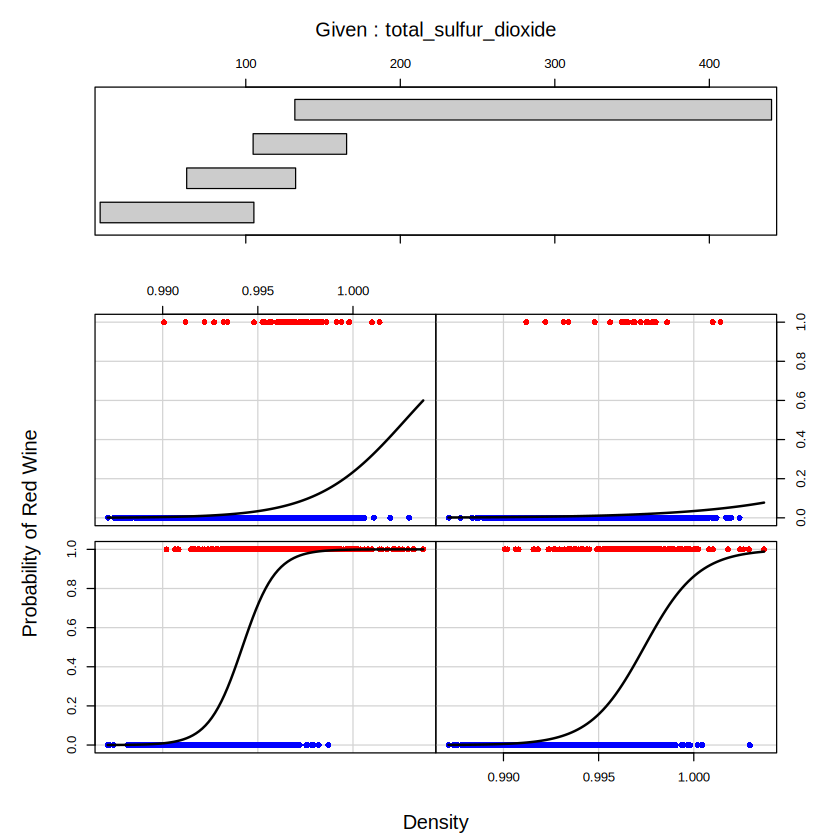

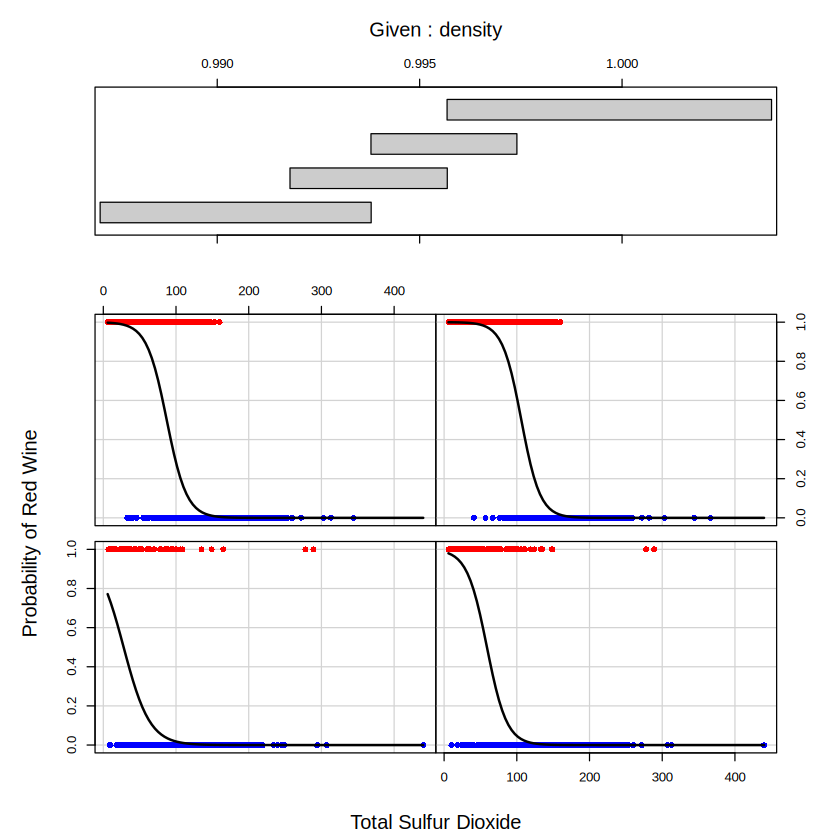

In [14]:
model_no_interaction <- glm(wine_type ~ density + total_sulfur_dioxide, data = wine_clean, family = "binomial")
model_with_interaction <- glm(wine_type ~ density * total_sulfur_dioxide, data = wine_clean, family = "binomial")

# coplot for model w/no interaction: wine type vs density conditioned on total sulfur dioxide
coplot(wine_type ~ density | total_sulfur_dioxide, data = wine_clean,
       panel = function(x, y, ...) {
         points(x[y == 1], y[y == 1], col = "red", pch = 16) #red wine
         points(x[y == 0], y[y == 0], col = "blue", pch = 16) #white wine
         fit <- glm(y ~ x, family = "binomial")
         curve(predict(fit, data.frame(x = x), type = "response"),
               add = TRUE, col = "black", lwd = 2)
          },
        xlab = "Density", ylab = "Probability of Red Wine", number = 4)

# coplot for model w/no interaction: wine type vs total sulfur dioxide conditioned on density
coplot(wine_type ~ total_sulfur_dioxide | density, data = wine_clean,
       panel = function(x, y, ...) {
         points(x[y == 1], y[y == 1], col = "red", pch = 16)
         points(x[y == 0], y[y == 0], col = "blue", pch = 16)
         fit <- glm(y ~ x, family = "binomial")
         curve(predict(fit, data.frame(x = x), type = "response"),
               add = TRUE, col = "black", lwd = 2)
         },
        xlab = "Total Sulfur Dioxide", ylab = "Probability of Red Wine", number = 4)


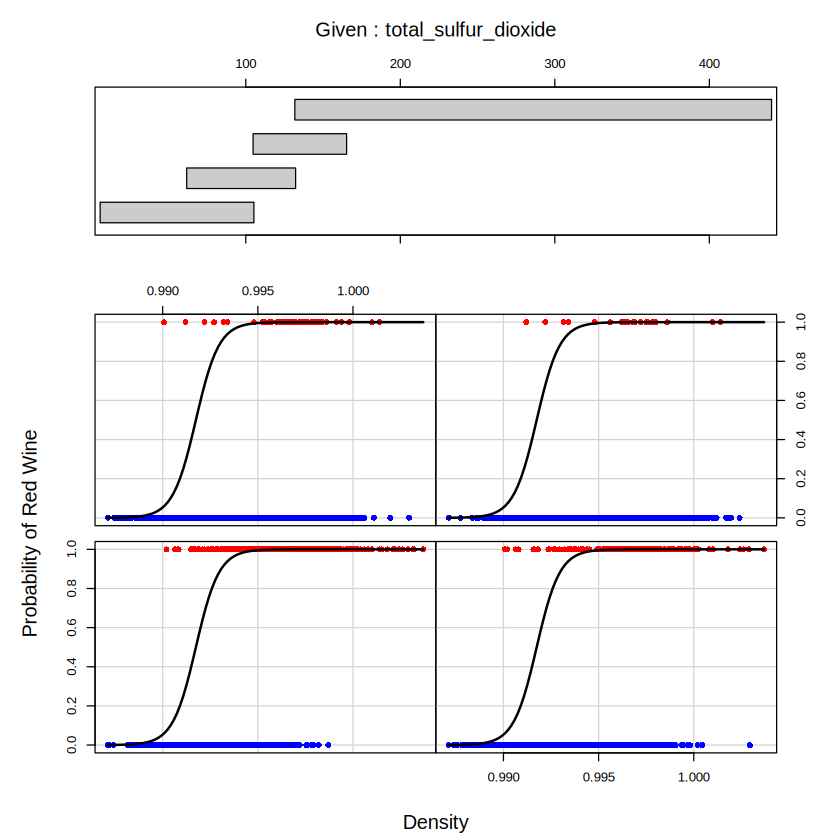

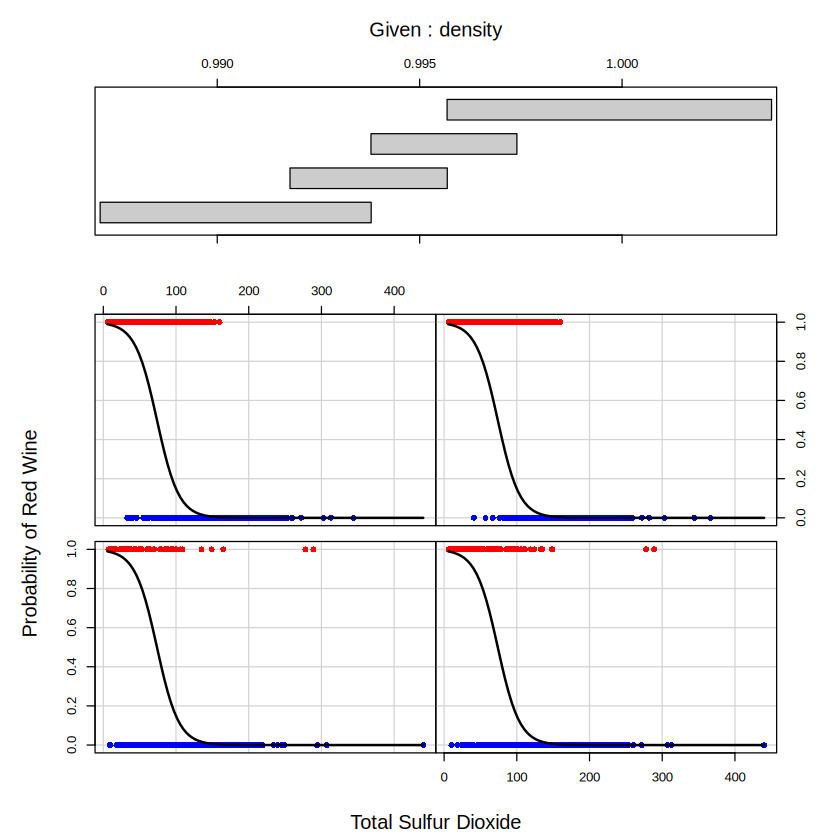

In [18]:
model_no_interaction <- glm(wine_type ~ density + total_sulfur_dioxide, data = wine_clean, family = "binomial")
model_with_interaction <- glm(wine_type ~ density * total_sulfur_dioxide, data = wine_clean, family = "binomial")

# coplot for model with interaction: wine type vs density conditioned on total sulfur dioxide
coplot(wine_type ~ density | total_sulfur_dioxide, data = wine_clean,
       panel = function(x, y, ...) {
         points(x[y == 1], y[y == 1], col = "red", pch = 16)
         points(x[y == 0], y[y == 0], col = "blue", pch = 16)
         curve(predict(model_with_interaction,
                       newdata = data.frame(density = x,
                       total_sulfur_dioxide = mean(x)), type = "response"),
               add = TRUE, col = "black", lwd = 2)
          },
        xlab = "Density", ylab = "Probability of Red Wine", number = 4)

#coplot for model with interaction: wine vs total_sulfur_dioxide conditioned on density

coplot(wine_type ~ total_sulfur_dioxide | density, data = wine_clean,
       panel = function(x, y, ...) {
         points(x[y == 1], y[y == 1], col = "red", pch = 16)
         points(x[y == 0], y[y == 0], col = "blue", pch = 16)
         curve(predict(model_with_interaction,
                       newdata = data.frame(
                         density = mean(wine_clean$density),
                         total_sulfur_dioxide = x), type = "response"),
               add = TRUE, col = "black", lwd = 2)
          },
       xlab = "Total Sulfur Dioxide", ylab = "Probability of Red Wine",
       number = 4)